# GO Analysis for WGCNA

Phase 1 and (subset of) Phase 2 oysters

Gene ontology of modules from [WGCNA](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/compare_phases/deseq_wgcna_ALL.ipynb) using the [new reference genome](https://www.ncbi.nlm.nih.gov/datasets/genome/GCF_053477285.1/). Following [Gurr code](https://github.com/SamGurr/Pgenerosa_OA_TagSeq/blob/main/TagSeq/Analysis/Scripts/GO_Analysis_WGCNA_all.R)

Since we don't have log fold change (because we aren't looking at differential expression), we can only do an over-representation analysis (ORA) - provide a gene list of interest (genes in a significantly correlated module) and a universal gene list (after filtering for wgcna - so *not* all genes in the CV genome, but rather what went in as input to wgcna)

## 0. load libraries

In [2]:
library(tidyverse)
library(goseq)
library(reshape2)
library(Rmisc)
library(ggpubr)
library(gridExtra)
library(forcats)
library(zoo)
library(ComplexHeatmap)
library(GO.db)
library(GSEABase)
library(clusterProfiler)

## 1. load data
WGCNA module membership, module colors, and goslim_generic.obo

#### A. gene annotation to GO.term - long format
matches GO terms to *C. virginica* genes - one GO term per row (so genes are duplicated among rows)

In [3]:
annot <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/Reference_genomes/Cvirginica_genome/annotations/newRef_geneGO.csv')
colnames(annot)[1] <- 'Gene'
colnames(annot)[2] <- 'GO.terms'

# One row for each gene and GO.term
term2gene <- annot %>%
  separate_rows(GO.terms, sep = ";") %>% # one row for each GO.term
  filter(!is.na(GO.terms) & GO.terms != "") %>% # remove genes without GO terms
  dplyr::select(term = GO.terms, gene = Gene) # rename columns for GO 

# 

head(term2gene)

term,gene
<chr>,<chr>
GO:0005261,LOC111099029
GO:0005886,LOC111099029
GO:0030001,LOC111099029
GO:0098655,LOC111099029
GO:0004930,LOC111099032
GO:0005886,LOC111099032


this becomes input for `enricher` down below

get term names for GO IDs

In [4]:
# Extract GO term descriptions
go_terms <- unique(term2gene$term)

# Get descriptions from GO.db
term2name <- data.frame(
  term = go_terms,
  name = sapply(go_terms, function(x) {
    tryCatch({
      Term(GOTERM[[x]])
    }, error = function(e) {
      NA_character_
    })
  })
)

# Remove NAs
term2name <- term2name[!is.na(term2name$name), ]

# View
head(term2name)    

,term,name
,<chr>,<chr>
GO:0005261,GO:0005261,monoatomic cation channel activity
GO:0005886,GO:0005886,plasma membrane
GO:0030001,GO:0030001,metal ion transport
GO:0098655,GO:0098655,monoatomic cation transmembrane transport
GO:0004930,GO:0004930,G protein-coupled receptor activity
GO:0007186,GO:0007186,G protein-coupled receptor signaling pathway


#### B. GOslim data

GO Slim - higher level of GO used to summarize GO results into broader categories (the parent terms)

In [5]:
slim <- getOBOCollection("http://current.geneontology.org/ontology/subsets/goslim_generic.obo")
class(slim)

[1] "OBOCollection"
attr(,"package")
[1] "GSEABase"

In [6]:
# 1. Get the GO IDs
slim_ids <- ids(slim)

# 2. Get the IDs that belong to the generic subset
slim_ids <- ids(slim["goslim_generic" ])

# 3. Get the terms for those specific IDs
# use the GO.db package because it's much faster and more reliable for names
slim_terms <- Term(slim_ids)

# 4. Create lookup table 
slim_lookup <- data.frame(
  SlimID = names(slim_terms), # parent ID
  GOSlim_Bin = as.character(slim_terms), # biological term
  stringsAsFactors = FALSE
)

head(slim_lookup)

,SlimID,GOSlim_Bin
,<chr>,<chr>
1,GO:0000228,nuclear chromosome
2,GO:0000278,mitotic cell cycle
3,GO:0000910,cytokinesis
4,GO:0001618,virus receptor activity
5,GO:0002181,cytoplasmic translation
6,GO:0002376,immune system process


this table can be used to assign GO terms to broader categories - however, this table only contains parent terms (SlimID), so cannot directly be merged with GO results - need to match the parent terms to the GO IDs

In [7]:
# 1. Get a list of all ancestors for every GO term in WGCNA results
# This creates a mapping of Specific_ID -> All_Ancestors
all_ancestors <- as.list(GOBPANCESTOR)

# lookup vector - parent GO terms
target_slim_ids <- unique(slim_lookup$SlimID)

# 2. make lookup function
find_slim_parent <- function(specific_id, slim_ids) {
  if (is.na(specific_id)) return(NA_character_) # if GO term isn't in ancestor lookup
  if (specific_id %in% slim_ids) return(specific_id) # if GO term is the parent term
  
  # Get ancestors from the GO.db object
  ancestors <- all_ancestors[[specific_id]]
  
  if (is.null(ancestors)) return(NA_character_) # if no ancestor term
  
  # Find which ancestors are in your Slim list
  match <- intersect(ancestors, slim_ids)
  
  if (length(match) == 0) return(NA_character_)
  return(as.character(match[1])) 
}


#### C. Gene info
read in gene info from [deseq_wgcna_ALL.ipynb](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/compare_phases/deseq_wgcna_ALL.ipynb)

contains the gene name, matching GO terms, module color, gene significance (GS) for every treatment, and module membership (MM) for each module

In [8]:
geneInfo <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/wgcna_GeneInfo.csv') 
head(geneInfo) 

,Gene,ModuleColor,GS.Phase_oys,GS.temp_code,GS.DO_code,GS.recent_expo_both,GS.recent_expo_control,GS.recent_expo_hypoxic,GS.recent_expo_warm,p.GS.GS.Phase_oys,⋯,MMlightcyan,MMturquoise,MMgreenyellow,MMpurple,MMblue,MMpink,MMlightgreen,MMtan,MMblack,MMlightyellow
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,brown,-0.05863409,0.2030722,-0.163921269,0.00872477,-0.03681398,-0.19939143,0.22107144,0.702023390,⋯,0.04502247,0.05262517,-0.243663728,-0.04626566,0.06437416,-0.12373695,-0.1746286,-0.21846163,0.359995578,0.2499328
2,LOC144621269,brown,-0.31994027,0.2001027,-0.146284772,-0.03783631,-0.10043513,-0.13231629,0.26296400,0.032153388,⋯,0.13831195,-0.19872274,-0.004721947,-0.21079326,-0.16567972,-0.31523112,0.1246694,0.01052625,0.005500375,-0.1647214
3,LOC111120925,black,-0.07626536,-0.1227264,-0.072319026,0.03194097,0.25880996,-0.11605957,-0.16976949,0.618531114,⋯,-0.15155786,-0.17199651,0.148164131,0.01207836,0.11388703,-0.04604726,0.3740263,0.34744260,0.930622268,0.1872893
4,LOC144621283,blue,0.43757481,0.1528333,-0.101086294,0.11836101,0.05817095,-0.23594055,0.05773477,0.002647954,⋯,0.16361525,0.58097527,0.306101656,0.24127605,0.71622647,0.40722135,-0.3344669,0.27475596,0.068739224,0.3138972
5,LOC144621276,blue,0.56437341,0.2467170,0.006155075,0.21881169,-0.07531895,-0.21165236,0.06623924,0.000053912,⋯,-0.03803452,0.57098603,0.066961082,0.20805683,0.87206661,0.48010570,-0.2694058,0.46301703,0.071177400,0.1230955
6,LOC111115920,magenta,-0.06263278,0.2109318,0.229110664,0.35342260,-0.15841716,-0.08693024,-0.10503022,0.682736350,⋯,0.02637609,-0.04672040,-0.094459039,-0.01764933,-0.19702380,-0.08896998,-0.1553637,-0.30854768,-0.207578270,0.1053212


categorize gene info columns

I'll come back to this:
```# Get all column names once
all_cols <- names(geneInfo)

# 1. The 16 'Combo_treatments.GS' columns
combo_cols <- grep("^Combo_treatments\\.GS\\.", all_cols, value = TRUE)

# 2. Phase 1 & 2 Driver columns (Temp and DO)
p1_driver_cols <- grep("^phase1_(temp|DO)\\.GS\\.", all_cols, value = TRUE)
p2_driver_cols <- grep("^phase2_(temp|DO)\\.GS\\.", all_cols, value = TRUE)

# 3. Overall Phase Treatment columns
p1_overall_cols <- grep("^phase1_treatment\\.GS\\.", all_cols, value = TRUE)
p2_overall_cols <- grep("^phase2_treatment\\.GS\\.", all_cols, value = TRUE)

# 4. Module Membership (MM) colors
mm_cols <- grep("^MM", all_cols, value = TRUE)
```

#### Module membership
pull out just the genes, associated GO terms, and which module they're been assigned to

In [10]:
moduleMembership <-  geneInfo %>% dplyr::select(Gene, ModuleColor) # select for genes, GO.ids, modules
head(moduleMembership)

,Gene,ModuleColor
,<chr>,<chr>
1,LOC144621260,brown
2,LOC144621269,brown
3,LOC111120925,black
4,LOC144621283,blue
5,LOC144621276,blue
6,LOC111115920,magenta


#### D. universal list
this is the input gene list for wgcna before module assignment, but after gene filtering

In [14]:
universal_genes <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/wgcna_UniversalGeneList.csv')
colnames(universal_genes) <- 'gene'
head(universal_genes)

,gene
,<chr>
1,LOC144621260
2,LOC144621269
3,LOC111120925
4,LOC144621283
5,LOC144621276
6,LOC111115920


## 2. run GO enrichment
over-representation analysis

**input data:**
- universal_genes
- term2gene (matches gene LOC to GO term)
- term2name (matches GO term to GO description)
- geneInfo (output from WGCNA)

slim_lookup for matching parent GO terms to GO results

In [15]:
head(geneInfo)

,Gene,ModuleColor,GS.Phase_oys,GS.temp_code,GS.DO_code,GS.recent_expo_both,GS.recent_expo_control,GS.recent_expo_hypoxic,GS.recent_expo_warm,p.GS.GS.Phase_oys,⋯,MMlightcyan,MMturquoise,MMgreenyellow,MMpurple,MMblue,MMpink,MMlightgreen,MMtan,MMblack,MMlightyellow
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,brown,-0.05863409,0.2030722,-0.163921269,0.00872477,-0.03681398,-0.19939143,0.22107144,0.702023390,⋯,0.04502247,0.05262517,-0.243663728,-0.04626566,0.06437416,-0.12373695,-0.1746286,-0.21846163,0.359995578,0.2499328
2,LOC144621269,brown,-0.31994027,0.2001027,-0.146284772,-0.03783631,-0.10043513,-0.13231629,0.26296400,0.032153388,⋯,0.13831195,-0.19872274,-0.004721947,-0.21079326,-0.16567972,-0.31523112,0.1246694,0.01052625,0.005500375,-0.1647214
3,LOC111120925,black,-0.07626536,-0.1227264,-0.072319026,0.03194097,0.25880996,-0.11605957,-0.16976949,0.618531114,⋯,-0.15155786,-0.17199651,0.148164131,0.01207836,0.11388703,-0.04604726,0.3740263,0.34744260,0.930622268,0.1872893
4,LOC144621283,blue,0.43757481,0.1528333,-0.101086294,0.11836101,0.05817095,-0.23594055,0.05773477,0.002647954,⋯,0.16361525,0.58097527,0.306101656,0.24127605,0.71622647,0.40722135,-0.3344669,0.27475596,0.068739224,0.3138972
5,LOC144621276,blue,0.56437341,0.2467170,0.006155075,0.21881169,-0.07531895,-0.21165236,0.06623924,0.000053912,⋯,-0.03803452,0.57098603,0.066961082,0.20805683,0.87206661,0.48010570,-0.2694058,0.46301703,0.071177400,0.1230955
6,LOC111115920,magenta,-0.06263278,0.2109318,0.229110664,0.35342260,-0.15841716,-0.08693024,-0.10503022,0.682736350,⋯,0.02637609,-0.04672040,-0.094459039,-0.01764933,-0.19702380,-0.08896998,-0.1553637,-0.30854768,-0.207578270,0.1053212


In [17]:
modules <- setdiff(unique(geneInfo$ModuleColor), "grey")   # drop grey (unassigned) genes

all_res <- map_dfr(modules, function(mod) {
  target_genes <- geneInfo %>%
    filter(ModuleColor == mod) %>%
    pull(Gene)

  ego <- enricher(gene = target_genes,
                  universe = universal_genes$gene,
                  TERM2NAME = term2name,
                  TERM2GENE = term2gene,
                  pvalueCutoff = 0.05)

  if (is.null(ego) || nrow(as.data.frame(ego)) == 0) return(NULL)   # no enriched terms

  as.data.frame(ego) %>%
    mutate(module = mod)
})

head(all_res)

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,module
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>
GO:0005576...1,GO:0005576,extracellular region,62/1241,168/8432,6.026478e-13,1.952579e-10,1.687414e-10,LOC111104838/LOC111104989/LOC111127657/LOC111126687/LOC111127135/LOC111125392/LOC111111483/LOC111111604/LOC111111778/LOC111116489/LOC111117016/LOC111117500/LOC111117191/LOC144624363/LOC111116214/LOC111117428/LOC111117426/LOC111116198/LOC111116684/LOC144623481/LOC144624405/LOC111121724/LOC111138083/LOC111110868/LOC111134776/LOC111135614/LOC111132220/LOC111132939/LOC111132156/LOC111132881/LOC111133553/LOC144627859/LOC111107119/LOC144617825/LOC144627867/LOC111110365/LOC111105722/LOC111100180/LOC111107500/LOC111107493/LOC111107498/LOC144618404/LOC111133222/LOC111133953/LOC111134788/LOC111132808/LOC111138403/LOC111135120/LOC111130469/LOC111128613/LOC111128878/LOC111129707/LOC111118377/LOC111118401/LOC111111165/LOC111116019/LOC111115607/LOC111111646/LOC111111656/LOC144621662/LOC111114030/LOC111115673,62,brown
GO:0004867,GO:0004867,serine-type endopeptidase inhibitor activity,22/1241,36/8432,1.978525e-10,3.205211e-08,2.769935e-08,LOC111125392/LOC111110855/LOC144623882/LOC111111632/LOC111113073/LOC111117026/LOC111116489/LOC111117578/LOC111116736/LOC111117016/LOC111117500/LOC111117191/LOC144624363/LOC111116214/LOC111117428/LOC111117426/LOC111116198/LOC144623481/LOC111132135/LOC111110365/LOC111130469/LOC111128673,22,brown
GO:0051045,GO:0051045,negative regulation of membrane protein ectodomain proteolysis,13/1241,15/8432,1.130814e-09,1.221279e-07,1.055426e-07,LOC111105476/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111111461/LOC111111642,13,brown
GO:0008191,GO:0008191,metalloendopeptidase inhibitor activity,13/1241,16/8432,5.215300e-09,3.379515e-07,2.920568e-07,LOC111105476/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111111461/LOC111111642,13,brown
GO:0010951,GO:0010951,negative regulation of endopeptidase activity,13/1241,16/8432,5.215300e-09,3.379515e-07,2.920568e-07,LOC111105476/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111111461/LOC111111642,13,brown
GO:0055085,GO:0055085,transmembrane transport,58/1241,191/8432,1.928874e-08,1.041592e-06,9.001414e-07,LOC111105096/LOC111104195/LOC144617743/LOC144617666/LOC111125054/LOC111121262/LOC111125188/LOC111127405/LOC111117465/LOC111113514/LOC111133608/LOC111099701/LOC111118148/LOC111134162/LOC111114348/LOC111133863/LOC111136323/LOC111132904/LOC111135536/LOC111138185/LOC111135950/LOC111133636/LOC111135230/LOC111132933/LOC111133441/LOC111106706/LOC111135935/LOC144618523/LOC144618521/LOC111133796/LOC111135027/LOC111135572/LOC111133430/LOC111135826/LOC111135987/LOC111135986/LOC111134436/LOC111127794/LOC111129857/LOC111128621/LOC111128619/LOC111128620/LOC111129973/LOC111127845/LOC111127778/LOC111130735/LOC111129557/LOC111130032/LOC111130033/LOC111130034/LOC111118110/LOC111119001/LOC111118617/LOC111121398/LOC111118868/LOC111120778/LOC144617628/LOC111113162,58,brown


remove modules that are not significantly correlated with any factor (magenta, lightyellow, lightcyan, greenyellow, black)

In [41]:
sig_res <- all_res %>%
  filter(!module %in% c("magenta", "lightyellow", "lightcyan",
                        "greenyellow", "black", "grey60"),
         p.adjust < 0.05) %>%
mutate(higher_expr = case_when(
    module %in% c('yellow', 'lightgreen', 'green', 'brown') ~ 'Phase 1',
    module %in% c('turquoise', 'tan', 'purple', 'pink', 'blue') ~ 'Phase 2',
    TRUE ~ NA)) 

    
dim(sig_res)
head(sig_res)

[1] 133  11

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,module,higher_expr
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>,<chr>
GO:0005576,GO:0005576,extracellular region,62/1241,168/8432,6.026478e-13,1.952579e-10,1.687414e-10,LOC111104838/LOC111104989/LOC111127657/LOC111126687/LOC111127135/LOC111125392/LOC111111483/LOC111111604/LOC111111778/LOC111116489/LOC111117016/LOC111117500/LOC111117191/LOC144624363/LOC111116214/LOC111117428/LOC111117426/LOC111116198/LOC111116684/LOC144623481/LOC144624405/LOC111121724/LOC111138083/LOC111110868/LOC111134776/LOC111135614/LOC111132220/LOC111132939/LOC111132156/LOC111132881/LOC111133553/LOC144627859/LOC111107119/LOC144617825/LOC144627867/LOC111110365/LOC111105722/LOC111100180/LOC111107500/LOC111107493/LOC111107498/LOC144618404/LOC111133222/LOC111133953/LOC111134788/LOC111132808/LOC111138403/LOC111135120/LOC111130469/LOC111128613/LOC111128878/LOC111129707/LOC111118377/LOC111118401/LOC111111165/LOC111116019/LOC111115607/LOC111111646/LOC111111656/LOC144621662/LOC111114030/LOC111115673,62,brown,Phase 1
GO:0004867,GO:0004867,serine-type endopeptidase inhibitor activity,22/1241,36/8432,1.978525e-10,3.205211e-08,2.769935e-08,LOC111125392/LOC111110855/LOC144623882/LOC111111632/LOC111113073/LOC111117026/LOC111116489/LOC111117578/LOC111116736/LOC111117016/LOC111117500/LOC111117191/LOC144624363/LOC111116214/LOC111117428/LOC111117426/LOC111116198/LOC144623481/LOC111132135/LOC111110365/LOC111130469/LOC111128673,22,brown,Phase 1
GO:0051045,GO:0051045,negative regulation of membrane protein ectodomain proteolysis,13/1241,15/8432,1.130814e-09,1.221279e-07,1.055426e-07,LOC111105476/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111111461/LOC111111642,13,brown,Phase 1
GO:0008191,GO:0008191,metalloendopeptidase inhibitor activity,13/1241,16/8432,5.215300e-09,3.379515e-07,2.920568e-07,LOC111105476/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111111461/LOC111111642,13,brown,Phase 1
GO:0010951,GO:0010951,negative regulation of endopeptidase activity,13/1241,16/8432,5.215300e-09,3.379515e-07,2.920568e-07,LOC111105476/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111111461/LOC111111642,13,brown,Phase 1
GO:0055085,GO:0055085,transmembrane transport,58/1241,191/8432,1.928874e-08,1.041592e-06,9.001414e-07,LOC111105096/LOC111104195/LOC144617743/LOC144617666/LOC111125054/LOC111121262/LOC111125188/LOC111127405/LOC111117465/LOC111113514/LOC111133608/LOC111099701/LOC111118148/LOC111134162/LOC111114348/LOC111133863/LOC111136323/LOC111132904/LOC111135536/LOC111138185/LOC111135950/LOC111133636/LOC111135230/LOC111132933/LOC111133441/LOC111106706/LOC111135935/LOC144618523/LOC144618521/LOC111133796/LOC111135027/LOC111135572/LOC111133430/LOC111135826/LOC111135987/LOC111135986/LOC111134436/LOC111127794/LOC111129857/LOC111128621/LOC111128619/LOC111128620/LOC111129973/LOC111127845/LOC111127778/LOC111130735/LOC111129557/LOC111130032/LOC111130033/LOC111130034/LOC111118110/LOC111119001/LOC111118617/LOC111121398/LOC111118868/LOC111120778/LOC144617628/LOC111113162,58,brown,Phase 1


In [38]:
unique(sig_res$module)

[1] "brown"      "blue"       "turquoise"  "lightgreen" "yellow"    
[6] "green"      "pink"       "tan"        "purple"

what if we remove GO terms - look at just GOSlim categories

In [39]:
sig_res$GeneRatio <- sapply(strsplit(sig_res$GeneRatio, "/"), function(x) {
  as.numeric(x[1]) / as.numeric(x[2])
})

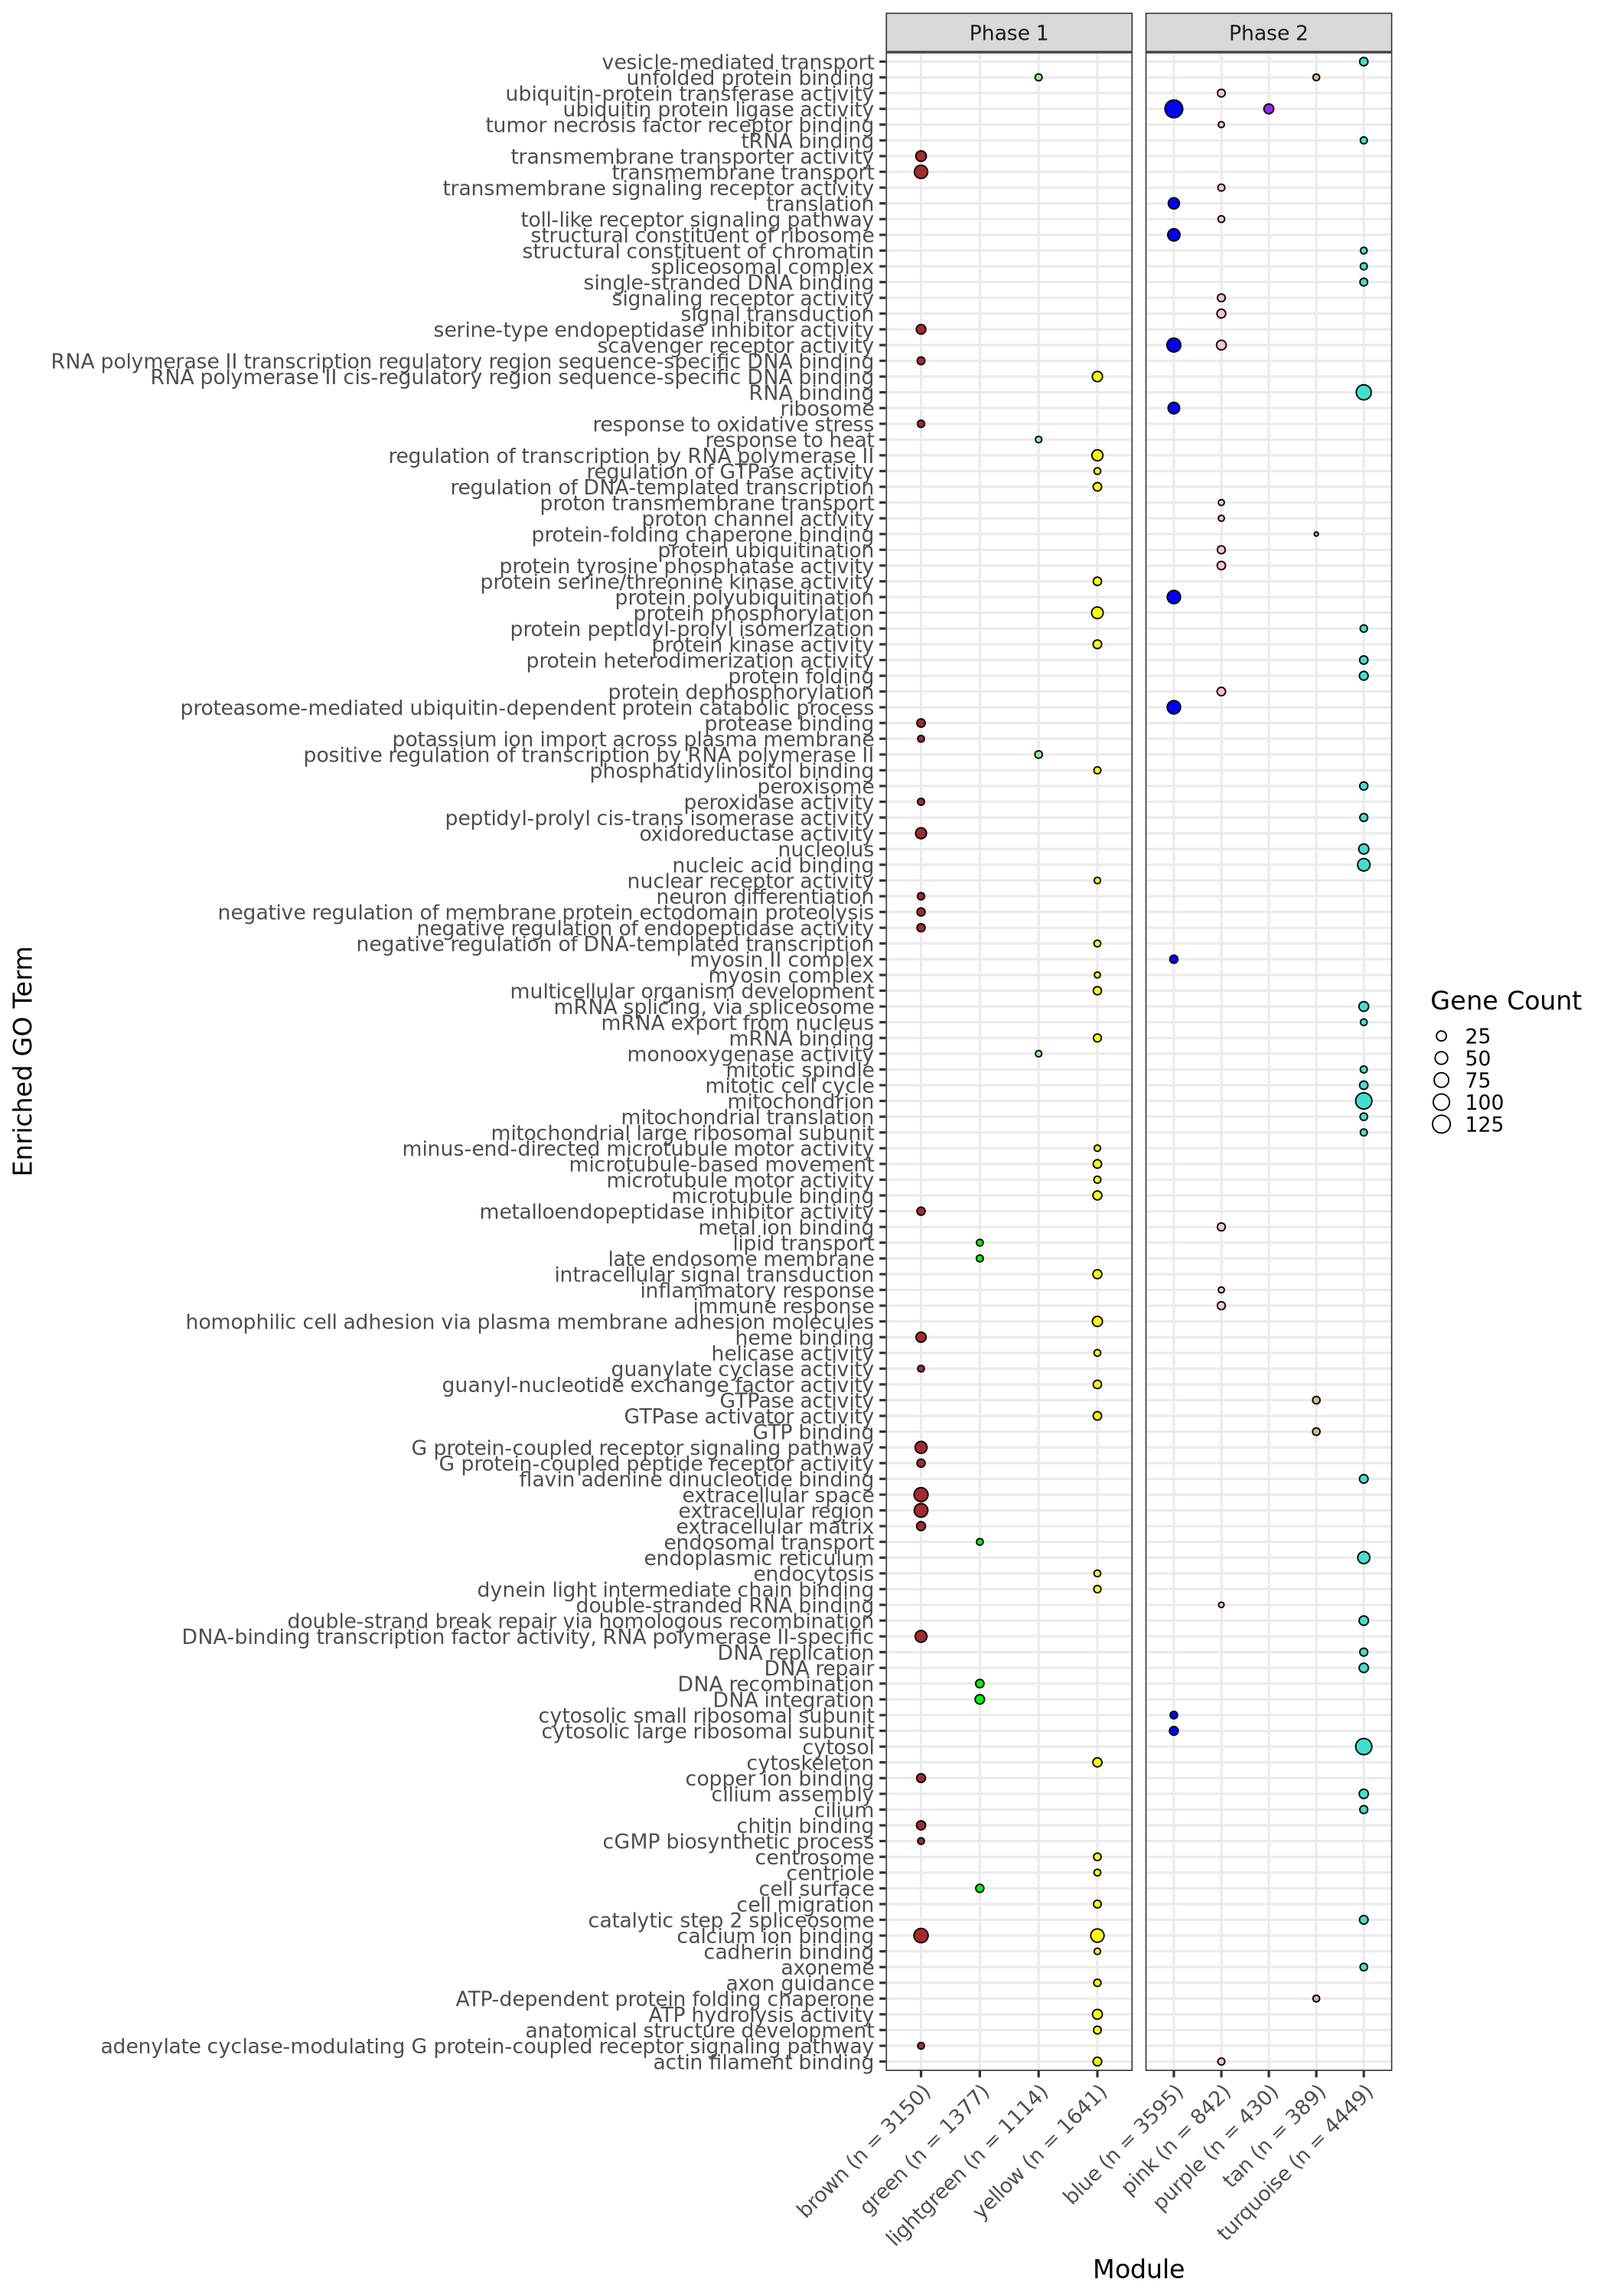

In [57]:
options(repr.plot.height = 25, repr.plot.width = 17.5)

module_gene_counts <- geneInfo %>%
  dplyr::count(ModuleColor)

module_labels <- setNames(
  paste0(module_gene_counts$ModuleColor, " (n = ", module_gene_counts$n, ")"),
  module_gene_counts$ModuleColor
)

ggplot(sig_res, aes(
  x = module,
  y = Description,
  size = Count,
  fill = module
)) +
  geom_point(shape = 21, color = "black", stroke = 0.8) +
facet_wrap(~higher_expr, scales = 'free_x') +
  guides(color = 'none') +
  #scale_color_manual(values = c('black', 'blue', 'red')) +
scale_fill_identity() +
  scale_x_discrete(labels = module_labels) +
  labs(
    x = "Module",
    y = "Enriched GO Term",
    size = "Gene Count"
  ) +
  theme_bw(base_size = 20) +
theme(axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1))

### adding GOslim

In [58]:
mod.mapped <- sig_res %>%
  # Process each row's ID individually
  rowwise() %>%
  # use function from earlier to map parent term to GO ID
  mutate(SlimID = find_slim_parent(ID, target_slim_ids)) %>% 
  ungroup() %>%
  # Join with lookup table to get 'GOSlim_Bin'
  left_join(slim_lookup, by = "SlimID")

# Remove terms that didn't map to a slim category if desired
mod.slim <- mod.mapped %>%
  filter(!is.na(GOSlim_Bin))

head(mod.slim)

ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,module,higher_expr,SlimID,GOSlim_Bin
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
GO:0005576,extracellular region,62/1241,168/8432,6.026478e-13,1.952579e-10,1.687414e-10,LOC111104838/LOC111104989/LOC111127657/LOC111126687/LOC111127135/LOC111125392/LOC111111483/LOC111111604/LOC111111778/LOC111116489/LOC111117016/LOC111117500/LOC111117191/LOC144624363/LOC111116214/LOC111117428/LOC111117426/LOC111116198/LOC111116684/LOC144623481/LOC144624405/LOC111121724/LOC111138083/LOC111110868/LOC111134776/LOC111135614/LOC111132220/LOC111132939/LOC111132156/LOC111132881/LOC111133553/LOC144627859/LOC111107119/LOC144617825/LOC144627867/LOC111110365/LOC111105722/LOC111100180/LOC111107500/LOC111107493/LOC111107498/LOC144618404/LOC111133222/LOC111133953/LOC111134788/LOC111132808/LOC111138403/LOC111135120/LOC111130469/LOC111128613/LOC111128878/LOC111129707/LOC111118377/LOC111118401/LOC111111165/LOC111116019/LOC111115607/LOC111111646/LOC111111656/LOC144621662/LOC111114030/LOC111115673,62,brown,Phase 1,GO:0005576,extracellular region
GO:0051045,negative regulation of membrane protein ectodomain proteolysis,13/1241,15/8432,1.130814e-09,1.221279e-07,1.055426e-07,LOC111105476/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111111461/LOC111111642,13,brown,Phase 1,GO:0030163,protein catabolic process
GO:0055085,transmembrane transport,58/1241,191/8432,1.928874e-08,1.041592e-06,9.001414e-07,LOC111105096/LOC111104195/LOC144617743/LOC144617666/LOC111125054/LOC111121262/LOC111125188/LOC111127405/LOC111117465/LOC111113514/LOC111133608/LOC111099701/LOC111118148/LOC111134162/LOC111114348/LOC111133863/LOC111136323/LOC111132904/LOC111135536/LOC111138185/LOC111135950/LOC111133636/LOC111135230/LOC111132933/LOC111133441/LOC111106706/LOC111135935/LOC144618523/LOC144618521/LOC111133796/LOC111135027/LOC111135572/LOC111133430/LOC111135826/LOC111135987/LOC111135986/LOC111134436/LOC111127794/LOC111129857/LOC111128621/LOC111128619/LOC111128620/LOC111129973/LOC111127845/LOC111127778/LOC111130735/LOC111129557/LOC111130032/LOC111130033/LOC111130034/LOC111118110/LOC111119001/LOC111118617/LOC111121398/LOC111118868/LOC111120778/LOC144617628/LOC111113162,58,brown,Phase 1,GO:0055085,transmembrane transport
GO:0016491,oxidoreductase activity,33/1241,92/8432,3.529756e-07,1.143641e-05,9.883317e-06,LOC111134951/LOC111127563/LOC144623055/LOC111116698/LOC111117873/LOC111103632/LOC111111108/LOC111134564/LOC144626876/LOC144626878/LOC111133149/LOC111138454/LOC111135001/LOC111136253/LOC111133732/LOC111134409/LOC111138284/LOC111136225/LOC111137992/LOC111136100/LOC111105928/LOC144627547/LOC111138327/LOC111138328/LOC111128875/LOC111128455/LOC111118934/LOC111118924/LOC111118881/LOC111110826/LOC144621368/LOC111111096/LOC111114035,33,brown,Phase 1,GO:0016491,oxidoreductase activity
GO:0007186,G protein-coupled receptor signaling pathway,43/1241,151/8432,8.423646e-06,2.274385e-04,1.965517e-04,LOC111104484/LOC111104100/LOC111124959/LOC144623044/LOC111126929/LOC111116095/LOC111113548/LOC144624076/LOC111112680/LOC111103268/LOC111126761/LOC111118494/LOC111120815/LOC111133681/LOC111134122/LOC111135090/LOC111107321/LOC144618166/LOC111110420/LOC111110409/LOC111106352/LOC111133698/LOC111128854/LOC111129475/LOC111130376/LOC111110890/LOC111130789/LOC111127955/LOC111130027/LOC111128946/LOC111111622/LOC111121622/LOC111118709/LOC111118445/LOC111118615/LOC111119095/LOC111120724/LOC111118787/LOC111117998/LOC111118486/LOC111121449/LOC111110886/LOC111116167,43,brown,Phase 1,GO:0023052,signaling
GO:0031012,extracellular matrix,18/1241,48/8432,8.336337e-05,1.800649e-03,1.556116e-03,LOC111105476/LOC111105502/LOC111099972/LOC111126687/LOC111104524/LOC111105721/LOC111112764/LOC111106004/LOC111107102/LOC111106132/LOC111110389/LOC111110387/LOC111107199/LOC111105736/LOC111135787/LOC111128958/LOC111111461/LOC111111642,18,brown,Phase 1,GO:003

### Module-Trait GO Enrichment

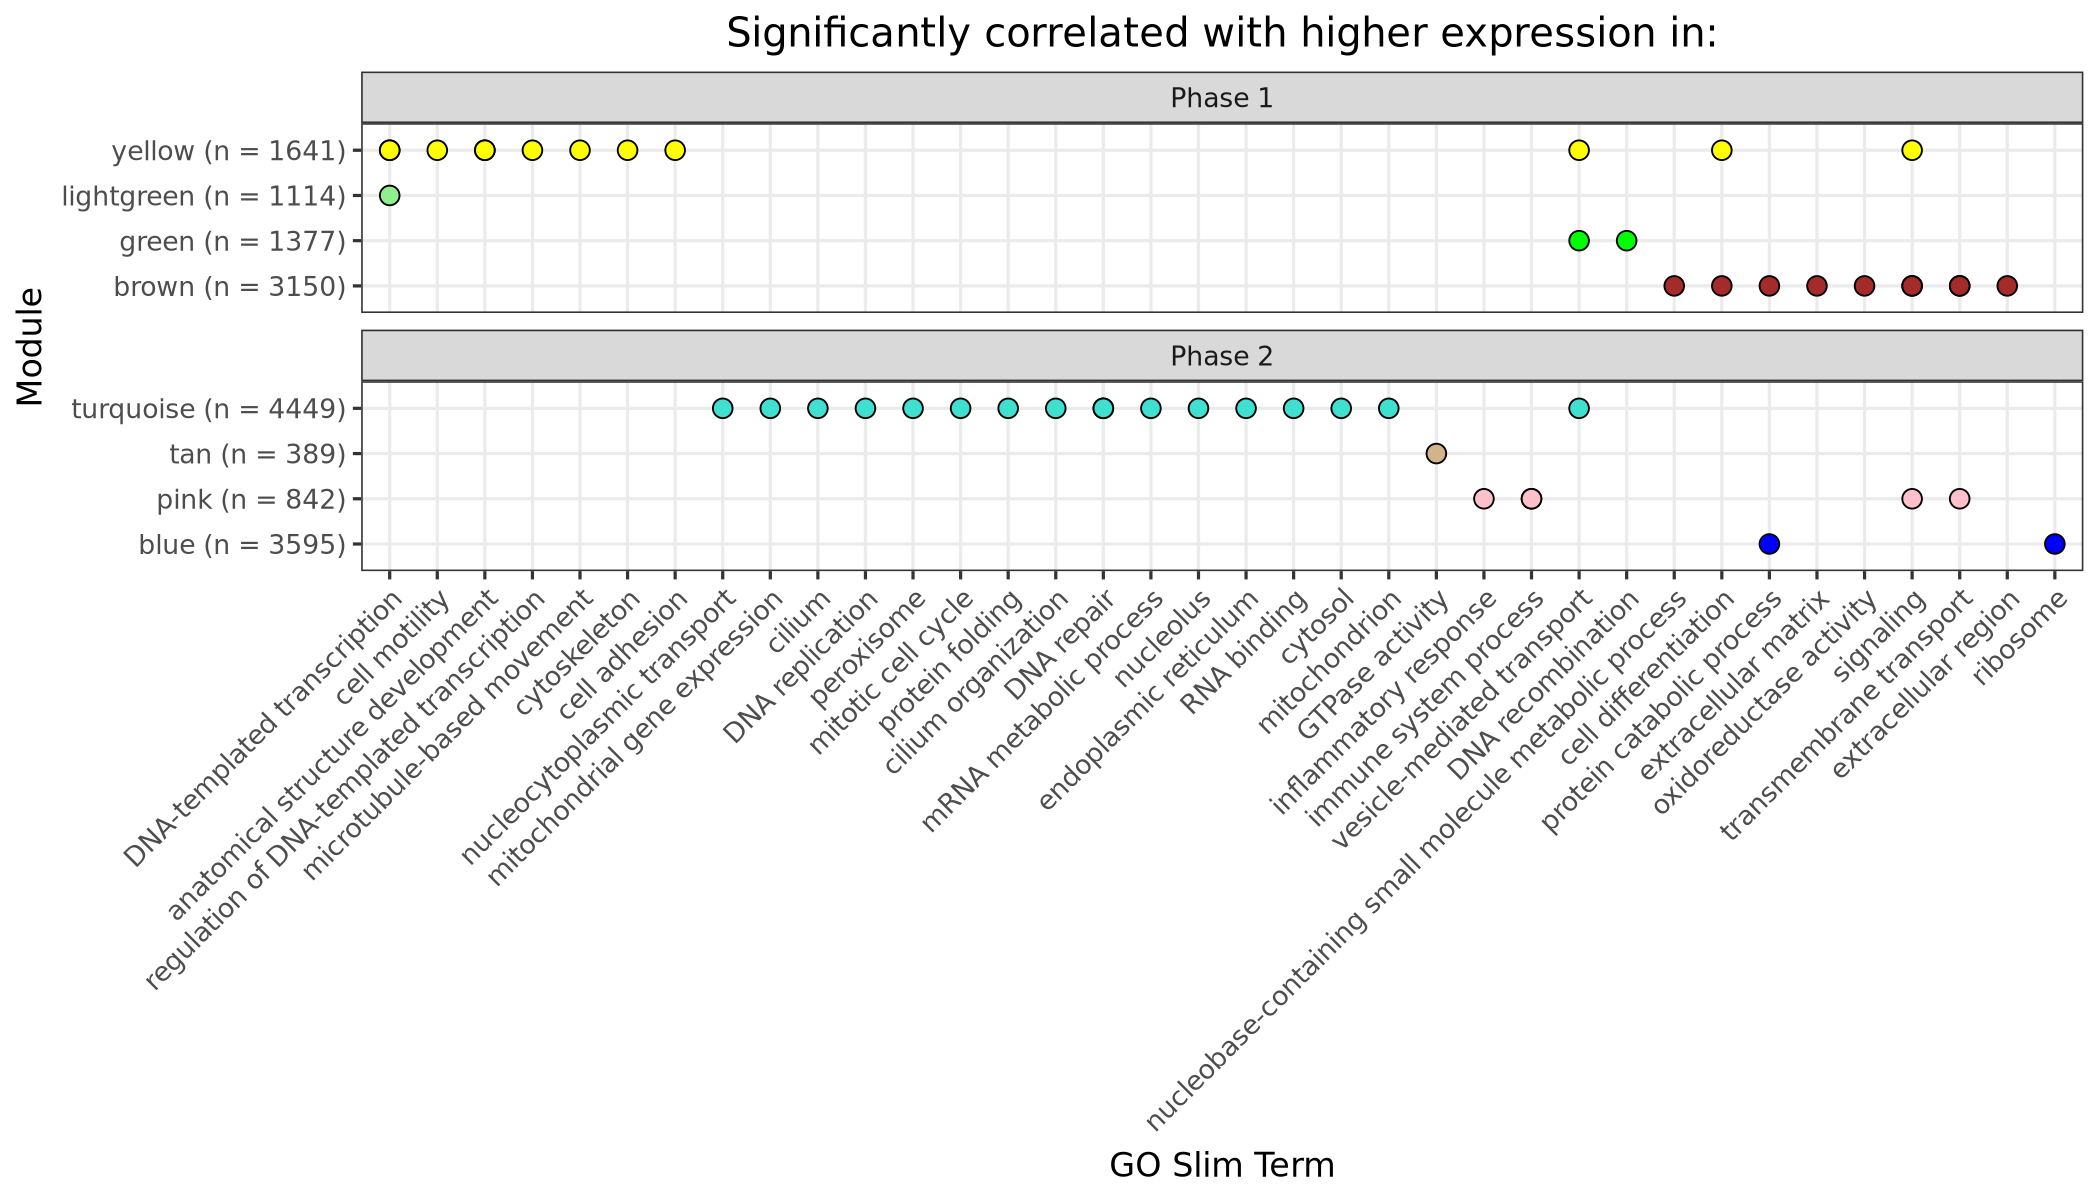

In [73]:
options(repr.plot.height = 10, repr.plot.width = 17.5)

module_gene_counts <- geneInfo %>%
  dplyr::count(ModuleColor)

module_labels <- setNames(
  paste0(module_gene_counts$ModuleColor, " (n = ", module_gene_counts$n, ")"),
  module_gene_counts$ModuleColor
)

ggplot(mod.slim2, aes(
  x = module,
  y = GOSlim_Bin,
  fill = module
)) +
  geom_point(shape = 21, color = "black", stroke = 0.8, size = 5) +
  scale_fill_identity() +
  scale_x_discrete(labels = module_labels) +
  labs(
    x = "Module",
    y = "GO Slim Term",
      title = 'Significantly correlated with higher expression in:' 
  ) +
  facet_wrap(~higher_expr, nrow = 2, scales = "free_y") +
  coord_flip() +
  theme_bw(base_size = 20) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),
       plot.title = element_text(hjust = 0.5))